In [5]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 
import shap
import warnings 
warnings.filterwarnings("ignore")

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV,TimeSeriesSplit
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from linearmodels.panel import PooledOLS, PanelOLS, RandomEffects

from xgboost import XGBRegressor

from catboost import CatBoostRegressor

In [6]:
train_file =  "E:\MyFiles\Final_Training_Dataset_Leakage_Free.xlsx"
test_file = "E:\MyFiles\Original_Test_Dataset_2020_2024.xlsx"

In [7]:
train_df = pd.read_excel(train_file)
test_df = pd.read_excel(test_file)

In [8]:
train_df.head()

,COUNTRY NAME,YEAR,Ingdp,Inco2,Inrec,Incc,Into,Ininf,Inind
0,South Africa,2007,26.338330,9.102810,-0.324749,3.950784,3.230592,6.177812,4.045244
1,Russia,2005,27.686840,12.118983,1.830178,3.792690,3.485209,12.685304,4.038008
2,India,2014,28.314033,1.705177,1.921149,5.915078,3.319857,6.665657,3.890231
3,Russia,2017,27.961091,12.135732,1.752496,1.869469,3.423392,3.683331,3.847517
4,India,2003,27.543659,0.969745,1.637778,0.000000,3.313244,3.805859,3.420753


In [9]:
test_df.head()

,COUNTRY NAME,YEAR,Ingdp,Inco2,Inrec,Incc,Into,Ininf,Inind
0,Brazil,2020,28.196367,2.146646,3.852607,1.819475,2.970728,3.211768,3.475132
1,Brazil,2021,28.242894,2.415809,3.776737,2.295428,3.096639,8.301660,3.628501
2,Brazil,2022,28.272615,2.278896,3.864091,1.554930,3.127614,9.280106,3.658834
3,Brazil,2023,28.304517,2.274478,3.890797,1.394419,3.097574,4.593563,3.516495
4,Brazil,2024,28.338138,2.318265,3.904313,1.181857,3.041694,4.367464,3.571911


In [10]:
print("\nTraining data", train_df.info())
print("\nTesting data", test_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   COUNTRY NAME  600 non-null    object 
 1   YEAR          600 non-null    int64  
 2   Ingdp         600 non-null    float64
 3   Inco2         600 non-null    float64
 4   Inrec         600 non-null    float64
 5   Incc          600 non-null    float64
 6   Into          600 non-null    float64
 7   Ininf         600 non-null    float64
 8   Inind         600 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 42.3+ KB

Training data None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   COUNTRY NAME  25 non-null     object 
 1   YEAR          25 non-null     int64  
 2   Ingdp         25 non-null     float64
 3   Inco2         25 n

In [11]:
print("Training data shape:", train_df.shape)
print("Testing data shape :", test_df.shape)

Training data shape: (600, 9)
Testing data shape : (25, 9)


In [12]:
print("TRAINING PERIOD")
print("Years:", train_df["YEAR"].min(), "to", train_df["YEAR"].max())
print("Countries:", train_df["COUNTRY NAME"].nunique())
print("Observations:", len(train_df))

print("\nTESTING PERIOD")
print("Years:", test_df["YEAR"].min(), "to", test_df["YEAR"].max())
print("Countries:", test_df["COUNTRY NAME"].nunique())
print("Observations:", len(test_df))

TRAINING PERIOD
Years: 2000 to 2019
Countries: 5
Observations: 600

TESTING PERIOD
Years: 2020 to 2024
Countries: 5
Observations: 25


In [13]:
print("\nTraining countries:")
print(sorted(train_df["COUNTRY NAME"].unique()))

print("\nTesting countries:")
print(sorted(test_df["COUNTRY NAME"].unique()))


Training countries:
['Brazil', 'China', 'India', 'Russia', 'South Africa']

Testing countries:
['Brazil', 'China', 'India', 'Russia', 'South Africa']


In [14]:
print("\nTraining data columns", train_df.columns)
print("\nTesting data columns", test_df.columns)


Training data columns Index(['COUNTRY NAME', 'YEAR', 'Ingdp', 'Inco2', 'Inrec', 'Incc', 'Into',
       'Ininf', 'Inind'],
      dtype='object')

Testing data columns Index(['COUNTRY NAME', 'YEAR', 'Ingdp', 'Inco2', 'Inrec', 'Incc', 'Into',
       'Ininf', 'Inind'],
      dtype='object')


In [15]:
features = ["Inco2", "Inrec", "Incc", "Into", "Ininf", "Inind"]
target = "Ingdp"
analysis_variables = ["COUNTRY NAME", "YEAR"] + features + [target]
print("Predictors:", features)
print("\nTarget:", target)
print("\nAll analysis variables:", analysis_variables)

Predictors: ['Inco2', 'Inrec', 'Incc', 'Into', 'Ininf', 'Inind']

Target: Ingdp

All analysis variables: ['COUNTRY NAME', 'YEAR', 'Inco2', 'Inrec', 'Incc', 'Into', 'Ininf', 'Inind', 'Ingdp']


In [16]:
print("TRAINING DATA — MISSING VALUES")
print(train_df[analysis_variables].isnull().sum())

print("\nTESTING DATA — MISSING VALUES")
print(test_df[analysis_variables].isnull().sum())

TRAINING DATA — MISSING VALUES
COUNTRY NAME    0
YEAR            0
Inco2           0
Inrec           0
Incc            0
Into            0
Ininf           0
Inind           0
Ingdp           0
dtype: int64

TESTING DATA — MISSING VALUES
COUNTRY NAME    0
YEAR            0
Inco2           0
Inrec           0
Incc            0
Into            0
Ininf           0
Inind           0
Ingdp           0
dtype: int64


In [17]:
train_df = train_df[analysis_variables].copy()
test_df = test_df[analysis_variables].copy()

train_df = train_df.sort_values(
    ["YEAR", "COUNTRY NAME"]
).reset_index(drop=True)

test_df = test_df.sort_values(
    ["YEAR", "COUNTRY NAME"]
).reset_index(drop=True)

print("Training data shape:", train_df.shape)
print("Testing data shape :", test_df.shape)

print("\nTraining period:")
print(train_df["YEAR"].min(), "to", train_df["YEAR"].max())

print("\nTesting period:")
print(test_df["YEAR"].min(), "to", test_df["YEAR"].max())

print("\nTraining years:", train_df["YEAR"].unique())
print("\nTesting years:", test_df["YEAR"].unique())

Training data shape: (600, 9)
Testing data shape : (25, 9)

Training period:
2000 to 2019

Testing period:
2020 to 2024

Training years: [2000 2001 2002 2003 2004 2005 2006 2007 2008 2009 2010 2011 2012 2013
 2014 2015 2016 2017 2018 2019]

Testing years: [2020 2021 2022 2023 2024]


In [18]:
desc_train = train_df[[target] + features].describe().T
desc_train["median"] = train_df[[target] + features].median()
desc_train["skewness"] = train_df[[target] + features].skew()
print("TRAINING DATA — DESCRIPTIVE STATISTICS")
display(desc_train)

desc_test = test_df[[target] + features].describe().T
desc_test["median"] = test_df[[target] + features].median()
desc_test["skewness"] = test_df[[target] + features].skew()
print("\nTESTING DATA — DESCRIPTIVE STATISTICS")
display(desc_test)

TRAINING DATA — DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max,median,skewness
Ingdp,600.0,27.957041,1.035508,26.064599,27.457447,27.951294,28.364309,30.334033,27.951294,0.254936
Inco2,600.0,5.874275,4.018257,0.939790,1.997723,5.779946,8.812432,12.813840,5.779946,0.286127
Inrec,600.0,1.798999,1.366585,-1.171486,1.656081,1.849083,2.329965,3.810610,1.849083,-0.487854
Incc,600.0,3.096364,2.358211,0.000000,0.000000,3.743211,4.857146,6.933320,3.743211,-0.029765
Into,600.0,3.359780,0.245502,2.900790,3.168952,3.320011,3.460640,3.847730,3.320011,0.524348
Ininf,600.0,6.333549,4.431465,-0.731971,3.729506,5.678594,8.349267,21.477007,5.678594,1.450448
Inind,600.0,3.752813,0.308204,3.095848,3.561030,3.859208,3.997935,4.220888,3.859208,-0.674374



TESTING DATA — DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max,median,skewness
Ingdp,25.0,28.418009,1.267634,26.544260,28.026170,28.272615,28.814501,30.548149,28.272615,0.262918
Inco2,25.0,6.703394,4.352966,1.680400,2.274478,6.882639,9.230276,13.997772,6.882639,0.295980
Inrec,25.0,2.359469,0.918806,0.948676,1.778416,2.185232,2.741184,3.904313,2.185232,0.481559
Incc,25.0,1.756464,0.384263,1.103696,1.490340,1.759912,2.127311,2.296772,1.759912,-0.204025
Into,25.0,3.309051,0.200421,2.970728,3.190910,3.230920,3.459026,3.640017,3.230920,0.361886
Ininf,25.0,5.123437,3.024847,0.218129,3.232388,4.953036,6.694459,13.743680,4.953036,0.692623
Inind,25.0,3.763870,0.206444,3.475132,3.616266,3.709523,3.913527,4.184793,3.709523,0.707149


In [19]:
correlation_matrix = train_df[[target] + features].corr(method="pearson")
print("PEARSON CORRELATION MATRIX — TRAINING DATA")
display(correlation_matrix)

PEARSON CORRELATION MATRIX — TRAINING DATA


,Ingdp,Inco2,Inrec,Incc,Into,Ininf,Inind
Ingdp,1.000000,-0.226186,0.580203,0.243634,0.592904,-0.306395,-0.215222
Inco2,-0.226186,1.000000,-0.487473,-0.022070,0.231127,0.315546,0.613933
Inrec,0.580203,-0.487473,1.000000,-0.045818,-0.145233,0.045930,-0.716797
Incc,0.243634,-0.022070,-0.045818,1.000000,0.184352,-0.149482,0.178673
Into,0.592904,0.231127,-0.145233,0.184352,1.000000,-0.184254,0.468781
Ininf,-0.306395,0.315546,0.045930,-0.149482,-0.184254,1.000000,0.258748
Inind,-0.215222,0.613933,-0.716797,0.178673,0.468781,0.258748,1.000000


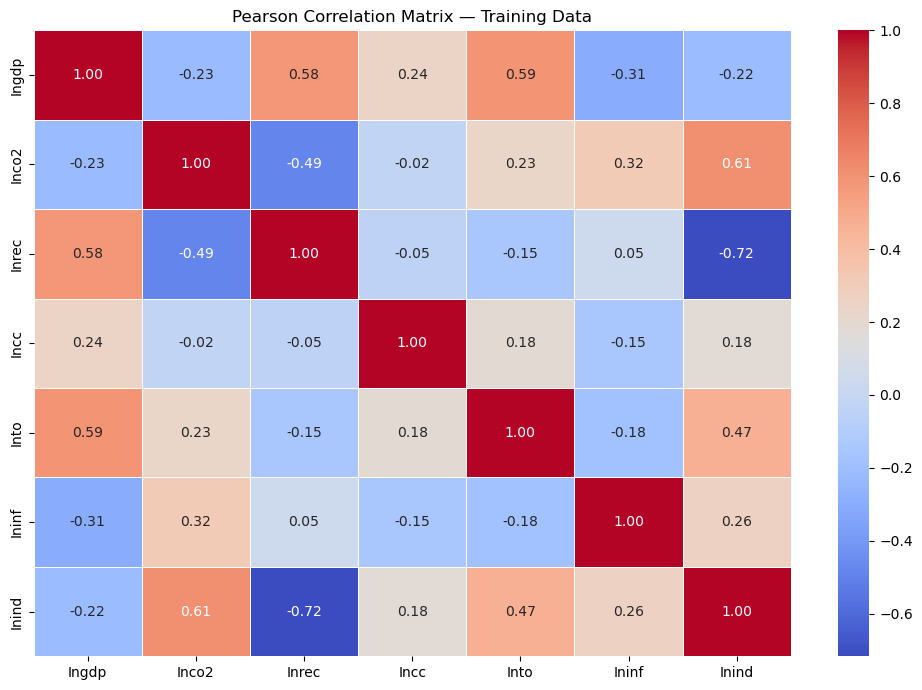

In [20]:
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Pearson Correlation Matrix — Training Data")
plt.tight_layout()
plt.show()

In [21]:
X_vif = train_df[features].copy()
X_vif = sm.add_constant(X_vif)
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif_data = vif_data[vif_data["Feature"] != "const"].reset_index(drop=True)
print("VIF — TRAINING DATA")
display(vif_data)

VIF — TRAINING DATA


,Feature,VIF
0,Inco2,1.755635
1,Inrec,3.323395
2,Incc,1.142731
3,Into,1.965607
4,Ininf,1.886576
5,Inind,5.176167


In [23]:
unique_years = train_df["YEAR"].unique()
print("Training years available for cross-validation:", unique_years)

tscv = TimeSeriesSplit(n_splits=3)
cv_splits = []
for fold, (train_year_idx, val_year_idx) in enumerate(tscv.split(unique_years), start=1):
    training_years = unique_years[train_year_idx]
    validation_years = unique_years[val_year_idx]
    training_indices = train_df.index[train_df["YEAR"].isin(training_years)].to_numpy()
    validation_indices = train_df.index[train_df["YEAR"].isin(validation_years)].to_numpy()
    cv_splits.append((training_indices, validation_indices))
    print(f"\nFold {fold}")
    print("Training years:", training_years.min(), "to", training_years.max())
    print("Validation years:", validation_years.min(), "to", validation_years.max())
    print( "Training observations:", len(training_indices))
    print( "Validation observations:", len(validation_indices))

Training years available for cross-validation: [2000 2001 2002 2003 2004 2005 2006 2007 2008 2009 2010 2011 2012 2013
 2014 2015 2016 2017 2018 2019]

Fold 1
Training years: 2000 to 2004
Validation years: 2005 to 2009
Training observations: 154
Validation observations: 150

Fold 2
Training years: 2000 to 2009
Validation years: 2010 to 2014
Training observations: 304
Validation observations: 149

Fold 3
Training years: 2000 to 2014
Validation years: 2015 to 2019
Training observations: 453
Validation observations: 147


In [24]:
X_train = train_df[features].copy()
y_train = train_df[target].copy()

X_test = test_df[features].copy()
y_test = test_df[target].copy()

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)

print("\nTraining target:", y_train.head())
print("\nTesting target:", y_test.head())

X_train shape: (600, 6)
y_train shape: (600,)
X_test shape : (25, 6)
y_test shape : (25,)

Training target: 0    27.800733
1    27.804935
2    27.776432
3    27.863046
4    27.806956
Name: Ingdp, dtype: float64

Testing target: 0    28.196367
1    30.333755
2    28.560753
3    27.983625
4    26.544260
Name: Ingdp, dtype: float64


In [25]:
rf_pipeline = Pipeline([("model", RandomForestRegressor( random_state=42, n_jobs=-1))])

In [26]:
rf_param_grid = {
    "model__n_estimators": [200, 300, 500, 700],
    "model__max_depth": [None, 3, 5, 7, 9],
    "model__min_samples_split": [2, 4],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", 1.0]
}
print("Random Forest hyperparameter grid:")
for parameter, values in rf_param_grid.items():
    print(f"{parameter}: {values}")

Random Forest hyperparameter grid:
model__n_estimators: [200, 300, 500, 700]
model__max_depth: [None, 3, 5, 7, 9]
model__min_samples_split: [2, 4]
model__min_samples_leaf: [1, 2]
model__max_features: ['sqrt', 1.0]


In [27]:
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=cv_splits,
    scoring="r2",
    n_jobs=-1,
    return_train_score=True,
    refit=True,
    verbose=1
)

print("Random Forest GridSearchCV created successfully.")
print("Number of parameter combinations:",
      len(rf_grid.get_params()["param_grid"]["model__n_estimators"]) *
      len(rf_grid.get_params()["param_grid"]["model__max_depth"]) *
      len(rf_grid.get_params()["param_grid"]["model__min_samples_split"]) *
      len(rf_grid.get_params()["param_grid"]["model__min_samples_leaf"]) *
      len(rf_grid.get_params()["param_grid"]["model__max_features"]))

Random Forest GridSearchCV created successfully.
Number of parameter combinations: 160


In [28]:
rf_grid.fit(X_train, y_train)
print("\nBest parameters:", rf_grid.best_params_)
print("\nBest CV score (negative MSE):", rf_grid.best_score_)
print("\nBest CV MSE:", -rf_grid.best_score_)
print("\nBest CV RMSE:", np.sqrt(-rf_grid.best_score_))

Fitting 3 folds for each of 160 candidates, totalling 480 fits

Best parameters: {'model__max_depth': None, 'model__max_features': 1.0, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}

Best CV score (negative MSE): 0.8175154115249229

Best CV MSE: -0.8175154115249229

Best CV RMSE: nan


In [29]:
rf_cv_results = pd.DataFrame(rf_grid.cv_results_)
rf_results_summary = rf_cv_results[
    [   "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "params"
    ]].copy()
rf_results_summary["mean_test_MSE"] = (-rf_results_summary["mean_test_score"])
rf_results_summary["mean_test_RMSE"] = np.sqrt(rf_results_summary["mean_test_MSE"])
rf_results_summary = rf_results_summary.sort_values("rank_test_score").reset_index(drop=True)
print("TOP 10 RANDOM FOREST CONFIGURATIONS")
display(rf_results_summary.head(10))         

TOP 10 RANDOM FOREST CONFIGURATIONS


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params,mean_test_MSE,mean_test_RMSE
0,1,0.817515,0.157066,0.998741,"{'model__max_depth': None, 'model__max_feature...",-0.817515,NaN
1,2,0.817432,0.157851,0.998743,"{'model__max_depth': None, 'model__max_feature...",-0.817432,NaN
2,3,0.817410,0.157133,0.998742,"{'model__max_depth': None, 'model__max_feature...",-0.817410,NaN
3,4,0.817313,0.157760,0.998740,"{'model__max_depth': 9, 'model__max_features':...",-0.817313,NaN
4,5,0.817296,0.158191,0.998743,"{'model__max_depth': None, 'model__max_feature...",-0.817296,NaN
5,6,0.817290,0.158481,0.998741,"{'model__max_depth': 9, 'model__max_features':...",-0.817290,NaN
6,7,0.817235,0.158155,0.998741,"{'model__max_depth': 9, 'model__max_features':...",-0.817235,NaN
7,8,0.817212,0.157592,0.998740,"{'model__max_depth': 9, 'model__max_features':...",-0.817212,NaN
8,9,0.816225,0.159278,0.998743,"{'model__max_depth': None, 'model__max_feature...",-0.816225,NaN
9,10,0.816184,0.158297,0.998721,"{'model__max_depth': 9, 'model__max_features':...",-0.816184,NaN


In [30]:
xgb_pipeline = Pipeline([
    (
        "model",
        XGBRegressor(
            objective="reg:squarederror",
            eval_metric="rmse",
            random_state=42,
            n_jobs=-1
        )
    )
])

In [31]:
xgb_param_grid = {
    "model__n_estimators": [200, 300, 500, 700],
    "model__max_depth": [2, 3, 5, 7],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}
print("XGBoost hyperparameter grid:")
for parameter, values in xgb_param_grid.items():
    print(f"{parameter}: {values}")
n_xgb_combinations = (
    len(xgb_param_grid["model__n_estimators"])
    * len(xgb_param_grid["model__max_depth"])
    * len(xgb_param_grid["model__learning_rate"])
    * len(xgb_param_grid["model__subsample"])
    * len(xgb_param_grid["model__colsample_bytree"])
)
print("\nTotal XGBoost parameter combinations:", n_xgb_combinations)
print("Total temporal-CV fits:", n_xgb_combinations * len(cv_splits))

XGBoost hyperparameter grid:
model__n_estimators: [200, 300, 500, 700]
model__max_depth: [2, 3, 5, 7]
model__learning_rate: [0.03, 0.05, 0.1]
model__subsample: [0.8, 1.0]
model__colsample_bytree: [0.8, 1.0]

Total XGBoost parameter combinations: 192
Total temporal-CV fits: 576


In [32]:
xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    cv=cv_splits,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    return_train_score=True,
    refit=True,
    verbose=1
)

In [33]:
xgb_grid.fit(X_train, y_train)
print("\nBest parameters:", xgb_grid.best_params_)
print("\nBest CV score (negative MSE):", xgb_grid.best_score_)
print("\nBest CV MSE:", -xgb_grid.best_score_)
print("\nBest CV RMSE:", np.sqrt(-xgb_grid.best_score_))

Fitting 3 folds for each of 192 candidates, totalling 576 fits

Best parameters: {'model__colsample_bytree': 1.0, 'model__learning_rate': 0.1, 'model__max_depth': 7, 'model__n_estimators': 200, 'model__subsample': 1.0}

Best CV score (negative MSE): -0.4867546208712239

Best CV MSE: 0.4867546208712239

Best CV RMSE: 0.6976780209174027


In [34]:
xgb_cv_results = pd.DataFrame(xgb_grid.cv_results_)
xgb_results_summary = xgb_cv_results[
    [   "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "params"
    ]].copy()
xgb_results_summary["mean_test_MSE"] = (-xgb_results_summary["mean_test_score"])
xgb_results_summary["mean_test_RMSE"] = np.sqrt(xgb_results_summary["mean_test_MSE"])
xgb_results_summary = xgb_results_summary.sort_values("rank_test_score").reset_index(drop=True)
print("TOP 10 XGBOOST CONFIGURATIONS")
display(xgb_results_summary.head(10))

TOP 10 XGBOOST CONFIGURATIONS


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params,mean_test_MSE,mean_test_RMSE
0,1,-0.486755,0.398493,-0.000944,"{'model__colsample_bytree': 1.0, 'model__learn...",0.486755,0.697678
1,1,-0.486755,0.398493,-0.000944,"{'model__colsample_bytree': 1.0, 'model__learn...",0.486755,0.697678
2,1,-0.486755,0.398493,-0.000944,"{'model__colsample_bytree': 1.0, 'model__learn...",0.486755,0.697678
3,1,-0.486755,0.398493,-0.000944,"{'model__colsample_bytree': 1.0, 'model__learn...",0.486755,0.697678
4,5,-0.487610,0.399711,-0.000944,"{'model__colsample_bytree': 1.0, 'model__learn...",0.487610,0.698291
5,6,-0.487612,0.399715,-0.000944,"{'model__colsample_bytree': 1.0, 'model__learn...",0.487612,0.698292
6,6,-0.487612,0.399715,-0.000944,"{'model__colsample_bytree': 1.0, 'model__learn...",0.487612,0.698292
7,6,-0.487612,0.399715,-0.000944,"{'model__colsample_bytree': 1.0, 'model__learn...",0.487612,0.698292
8,9,-0.487848,0.398290,-0.000944,"{'model__colsample_bytree': 1.0, 'model__learn...",0.487848,0.698461
9,9,-0.487848,0.398290,-0.000944,"{'model__colsample_bytree': 1.0, 'model__learn...",0.487848,0.698461


In [35]:
cat_pipeline = Pipeline([
    (
        "model",
        CatBoostRegressor(
            loss_function="RMSE",
            random_seed=42,
            verbose=0,
            thread_count=-1
        )
    )
])

In [36]:
cat_param_grid = {
    "model__iterations": [200, 300, 500, 700],
    "model__depth": [3, 5, 7, 9],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__l2_leaf_reg": [3, 5, 7]
}
for parameter, values in cat_param_grid.items():
    print(f"{parameter}: {values}")
n_cat_combinations = (
    len(cat_param_grid["model__iterations"])
    * len(cat_param_grid["model__depth"])
    * len(cat_param_grid["model__learning_rate"])
    * len(cat_param_grid["model__l2_leaf_reg"])
)
print("\nTotal CatBoost parameter combinations:", n_cat_combinations)
print("Total temporal-CV fits:", n_cat_combinations * len(cv_splits))

model__iterations: [200, 300, 500, 700]
model__depth: [3, 5, 7, 9]
model__learning_rate: [0.03, 0.05, 0.1]
model__l2_leaf_reg: [3, 5, 7]

Total CatBoost parameter combinations: 144
Total temporal-CV fits: 432


In [37]:
cat_grid = GridSearchCV(
    estimator=cat_pipeline,
    param_grid=cat_param_grid,
    cv=cv_splits,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
    return_train_score=True,
    refit=True,
    verbose=1
)

In [38]:
cat_grid.fit(X_train, y_train)
print("\nBest parameters:", cat_grid.best_params_)
print("\nBest CV score (negative MSE):", cat_grid.best_score_)
print("\nBest CV MSE:", -cat_grid.best_score_)
print("\nBest CV RMSE:", np.sqrt(-cat_grid.best_score_))

Fitting 3 folds for each of 144 candidates, totalling 432 fits

Best parameters: {'model__depth': 3, 'model__iterations': 700, 'model__l2_leaf_reg': 7, 'model__learning_rate': 0.1}

Best CV score (negative MSE): -0.27638300416188927

Best CV MSE: 0.27638300416188927

Best CV RMSE: 0.5257214130714948


In [39]:
cat_cv_results = pd.DataFrame(cat_grid.cv_results_)
cat_results_summary = cat_cv_results[[ "rank_test_score", "mean_test_score", "std_test_score", "mean_train_score", "params"]].copy()

cat_results_summary["mean_test_MSE"] = (-cat_results_summary["mean_test_score"])
cat_results_summary["mean_test_RMSE"] = np.sqrt(cat_results_summary["mean_test_MSE"])
cat_results_summary = cat_results_summary.sort_values("rank_test_score").reset_index(drop=True)
print("TOP 10 CATBOOST CONFIGURATIONS")
display(cat_results_summary.head(10))

TOP 10 CATBOOST CONFIGURATIONS


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params,mean_test_MSE,mean_test_RMSE
0,1,-0.276383,0.174187,-0.000949,"{'model__depth': 3, 'model__iterations': 700, ...",0.276383,0.525721
1,2,-0.276915,0.174754,-0.000963,"{'model__depth': 3, 'model__iterations': 500, ...",0.276915,0.526227
2,3,-0.279879,0.177944,-0.001073,"{'model__depth': 3, 'model__iterations': 300, ...",0.279879,0.529036
3,4,-0.281105,0.169274,-0.000946,"{'model__depth': 3, 'model__iterations': 700, ...",0.281105,0.530193
4,5,-0.281710,0.170005,-0.000955,"{'model__depth': 3, 'model__iterations': 500, ...",0.281710,0.530764
5,6,-0.282890,0.171558,-0.001022,"{'model__depth': 3, 'model__iterations': 300, ...",0.282890,0.531874
6,7,-0.283634,0.183103,-0.001305,"{'model__depth': 3, 'model__iterations': 200, ...",0.283634,0.532573
7,8,-0.286028,0.165674,-0.000945,"{'model__depth': 3, 'model__iterations': 700, ...",0.286028,0.534816
8,9,-0.286480,0.166260,-0.000950,"{'model__depth': 3, 'model__iterations': 500, ...",0.286480,0.535238
9,10,-0.287214,0.177459,-0.001225,"{'model__depth': 3, 'model__iterations': 200, ...",0.287214,0.535924


In [40]:
best_rf_pipeline = rf_grid.best_estimator_
best_xgb_pipeline = xgb_grid.best_estimator_
best_cat_pipeline = cat_grid.best_estimator_

print("Best Random Forest pipeline:", best_rf_pipeline)
print("\nBest XGBoost pipeline:", best_xgb_pipeline)
print("\nBest CatBoost pipeline:", best_cat_pipeline)

Best Random Forest pipeline: Pipeline(steps=[('model',
                 RandomForestRegressor(n_estimators=200, n_jobs=-1,
                                       random_state=42))])

Best XGBoost pipeline: Pipeline(steps=[('model',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample_bynode=None,
                              colsample_bytree=1.0, device=None,
                              early_stopping_rounds=None,
                              enable_categorical=True, eval_metric='rmse',
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.1,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
          

In [41]:
rf_test_pred = best_rf_pipeline.predict(X_test)
xgb_test_pred = best_xgb_pipeline.predict(X_test)
cat_test_pred = best_cat_pipeline.predict(X_test)

print("\nNumber of test observations:", len(y_test))

print("\nFirst 5 Random Forest predictions:", rf_test_pred[:5])
print("\nFirst 5 XGBoost predictions:", xgb_test_pred[:5])
print("\nFirst 5 CatBoost predictions:", cat_test_pred[:5])


Number of test observations: 25

First 5 Random Forest predictions: [28.11581396 30.30084362 28.44380211 27.79450441 26.62783545]

First 5 XGBoost predictions: [28.120546 27.7308   28.311878 27.614069 26.507494]

First 5 CatBoost predictions: [28.45978593 30.19962406 28.47453871 28.06342166 26.86251734]


In [42]:
rf_r2 = r2_score(y_test, rf_test_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_test_pred))
rf_mae = mean_absolute_error(y_test, rf_test_pred)
rf_mape = mean_absolute_percentage_error(y_test, rf_test_pred) * 100

xgb_r2 = r2_score(y_test, xgb_test_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_test_pred))
xgb_mae = mean_absolute_error(y_test, xgb_test_pred)
xgb_mape = mean_absolute_percentage_error(y_test, xgb_test_pred) * 100

cat_r2 = r2_score(y_test, cat_test_pred)
cat_rmse = np.sqrt(mean_squared_error(y_test, cat_test_pred))
cat_mae = mean_absolute_error(y_test, cat_test_pred)
cat_mape = mean_absolute_percentage_error(y_test, cat_test_pred) * 100


test_comparison = pd.DataFrame({
    "Model": ["Random Forest","XGBoost","CatBoost"],
    "R2": [rf_r2, xgb_r2, cat_r2],
    "RMSE": [rf_rmse, xgb_rmse, cat_rmse],
    "MAE": [rf_mae, xgb_mae, cat_mae],
    "MAPE (%)": [rf_mape, xgb_mape, cat_mape]})

test_comparison = test_comparison.sort_values("RMSE").reset_index(drop=True)
print("FINAL OUT-OF-SAMPLE PERFORMANCE — 2020–2024")
display(test_comparison)

FINAL OUT-OF-SAMPLE PERFORMANCE — 2020–2024


,Model,R2,RMSE,MAE,MAPE (%)
0,CatBoost,0.854860,0.473176,0.351605,1.240664
1,Random Forest,0.759186,0.609495,0.370087,1.340956
2,XGBoost,0.362418,0.991739,0.523911,1.768322


In [43]:
best_model_name = test_comparison.loc[test_comparison["RMSE"].idxmin(), "Model"]

print("BEST ML MODEL BASED ON 2020–2024 TEST RMSE:", best_model_name)
if best_model_name == "Random Forest":
    best_pipeline = best_rf_pipeline
    best_predictions = rf_test_pred

elif best_model_name == "XGBoost":
    best_pipeline = best_xgb_pipeline
    best_predictions = xgb_test_pred

elif best_model_name == "CatBoost":
    best_pipeline = best_cat_pipeline
    best_predictions = cat_test_pred

print("\nBest pipeline:", best_pipeline)

BEST ML MODEL BASED ON 2020–2024 TEST RMSE: CatBoost

Best pipeline: Pipeline(steps=[('model',
                 CatBoostRegressor(depth=3, iterations=700, l2_leaf_reg=7, learning_rate=0.1, loss_function='RMSE', random_seed=42, verbose=0))])
